In [1]:
from collections.abc import Mapping
from pathlib import Path
from typing import Any

import numpy as np
from dataeval.data import Indices, Limit, Shuffle, View
from datamaite import load_ic
from maite_datasets.image_classification import MilitaryVehicles, Ships
from numpy.typing import NDArray

data_root = Path("./data")
MilitaryVehicles(root=data_root, image_set="base", download=True)
MilitaryVehicles(root=data_root, image_set="train", as_datamaite=True)

vehicles_raw = load_ic(data_root / "militaryvehicles_datamaite_train" / "train", dataset_format="huggingface_vision")

# The loader groups samples by class folder, so raw index order is alphabetical by class.
# `Shuffle` imposes one seeded sequence, which is what keeps the reference and incoming
# slices below from being drawn from different corners of the label space. `View` is the
# same machinery a `ViewConfig` drives from the pipeline config; `resolve_indices()` hands
# back the shuffled source indices so each slice can be cut with `Indices`.
_order = View(vehicles_raw, [Shuffle(seed=42), Limit(2500)]).resolve_indices()

# Reference: the first 2 000 frames, unmodified
ref_maite = View(vehicles_raw, [Indices(_order[:2000])])

print(f"Reference: {len(ref_maite)} frames")
print(f"Sample shape: image={ref_maite[0][0].shape}, dtype={ref_maite[0][0].dtype}")

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Reference: 2000 frames
Sample shape: image=(3, 170, 297), dtype=uint8


In [2]:
ships = Ships(root=data_root, download=True)
print(f"Foreign source: {len(ships)} satellite frames, shape {ships[0][0].shape}")


class MisalignedImages:
    """Keeps each datum's annotation and replaces only its pixels.

    Parameters
    ----------
    dataset
        A MAITE-compatible dataset returning (image, target, metadata) tuples.
    foreign
        The dataset supplying replacement imagery.
    start, count
        The contiguous run of positions whose images are replaced.
    """

    def __init__(self, dataset: Any, foreign: Any, start: int, count: int) -> None:
        self._dataset = dataset
        self._foreign = foreign
        self._span = range(start, start + count)
        self.metadata = {"id": "misaligned_images", "original_metadata": dataset.metadata}

    def __len__(self) -> int:
        return len(self._dataset)

    def swapped(self, index: int) -> bool:
        """Whether this position carries foreign imagery."""
        return index in self._span

    def __getitem__(self, index: int) -> tuple[NDArray[Any], Any, Mapping[str, Any]]:
        image, target, metadata = self._dataset[index]
        if index in self._span:
            image = np.asarray(self._foreign[(index - self._span.start) % len(self._foreign)][0])
        return image, target, metadata


# Incoming: the next 500 frames, with positions 200-299 carrying ships imagery
incoming_maite = View(vehicles_raw, [Indices(_order[2000:2500])])
incoming_dataset = MisalignedImages(incoming_maite, ships, start=200, count=100)

n_swapped = sum(1 for i in range(len(incoming_dataset)) if incoming_dataset.swapped(i))
print(f"Incoming: {len(incoming_dataset)} frames")
print(f"  In-distribution (vehicles):        {len(incoming_dataset) - n_swapped}")
print(f"  Out-of-distribution (ships under vehicle labels): {n_swapped}")

Foreign source: 4000 satellite frames, shape (3, 80, 80)
Incoming: 500 frames
  In-distribution (vehicles):        400
  Out-of-distribution (ships under vehicle labels): 100


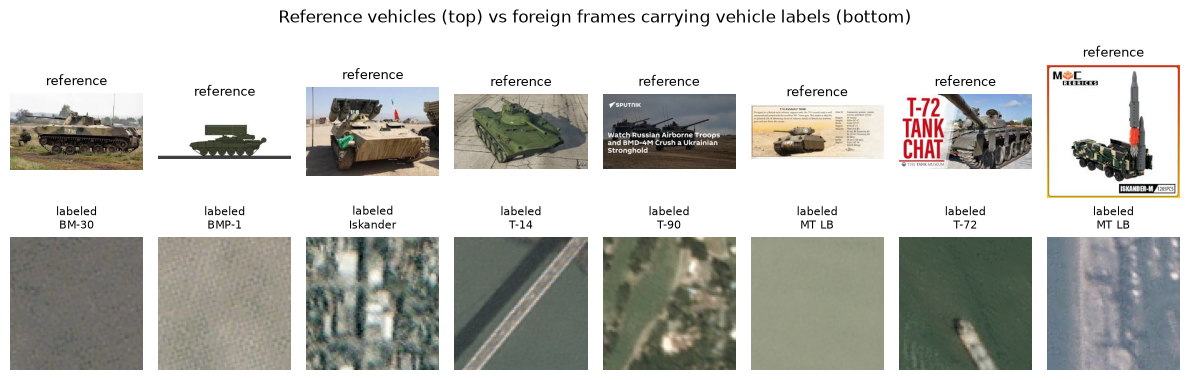

In [3]:
import matplotlib.pyplot as plt

index2label = vehicles_raw.metadata.get("index2label", {})
fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for col in range(8):
    img_arr = np.transpose(np.asarray(ref_maite[col][0]), (1, 2, 0))  # CHW -> HWC
    axes[0, col].imshow(img_arr)
    axes[0, col].set_title("reference", fontsize=9)
    axes[0, col].axis("off")

swapped_indices = [i for i in range(len(incoming_dataset)) if incoming_dataset.swapped(i)]
for col in range(8):
    idx = swapped_indices[col * 4]
    image, target, _ = incoming_dataset[idx]
    img_arr = np.transpose(np.asarray(image), (1, 2, 0))  # CHW -> HWC
    axes[1, col].imshow(img_arr)
    axes[1, col].set_title(f"labeled\n{index2label[int(np.argmax(target))]}", fontsize=8)
    axes[1, col].axis("off")

fig.suptitle("Reference vehicles (top) vs foreign frames carrying vehicle labels (bottom)", fontsize=12)
plt.tight_layout()
plt.show()

In [4]:
import torch
import torchvision

from dataeval_flow.config import (
    DatasetProtocolConfig,
    PipelineConfig,
    PreprocessingStep,
    PreprocessorConfig,
    SourceConfig,
)
from dataeval_flow.config.extractors import TorchExtractorConfig

# Cache weights locally for TorchExtractorConfig
model_dir = Path("./models")
model_dir.mkdir(exist_ok=True)
model_path = model_dir / "resnet18.pt"
if not model_path.exists():
    torch.save(torchvision.models.resnet18(weights="IMAGENET1K_V1").eval(), model_path)

# --- Datasets (in-memory via DatasetProtocolConfig) ---
ref_config = DatasetProtocolConfig(
    name="reference",
    format="maite",
    dataset=ref_maite,
)

incoming_config = DatasetProtocolConfig(
    name="incoming",
    format="maite",
    dataset=incoming_dataset,
)

# --- Extractor ---
preprocessor_config = PreprocessorConfig(
    name="imagenet",
    steps=[
        PreprocessingStep(step="Resize", params={"size": [224, 224], "antialias": True}),
        PreprocessingStep(step="ToDtype", params={"dtype": "float32", "scale": True}),
        PreprocessingStep(
            step="Normalize",
            params={"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
        ),
    ],
)

extractor_config = TorchExtractorConfig(
    name="resnet18",
    model_path=str(model_path),
    layer_name="avgpool",
    preprocessor="imagenet",
    batch_size=32,
)

In [5]:
from dataeval_flow import run_task
from dataeval_flow.config import TaskConfig
from dataeval_flow.workflows.shift import ShiftConfig

task = TaskConfig(
    name="vehicles-ood-check",
    workflow="vehicles-ood",
    sources=["ref_src", "inc_src"],
    extractor="resnet18",
)

config = PipelineConfig(
    max_processes=2,
    datasets=[ref_config, incoming_config],
    sources=[
        SourceConfig(name="ref_src", dataset="reference"),
        SourceConfig(name="inc_src", dataset="incoming"),
    ],
    preprocessors=[preprocessor_config],
    extractors=[extractor_config],
    workflows=[
        ShiftConfig.model_validate(
            {
                "name": "vehicles-ood",
                "detectors": [
                    {"type": "ood-kneighbors", "k": 10, "distance_metric": "cosine", "threshold_perc": 99.0},
                    {"type": "ood-domain-classifier", "n_folds": 3, "n_repeats": 3, "threshold_perc": 99.0},
                ],
                "checks": {
                    "ood": {"warning": 5.0, "info": 1.0},  # warn when 5% of a source's images are OOD
                    "ood-agreement": {"warning": 5.0, "info": 1.0},
                },
                "factor-deviation": {"max_items": 50},
            }
        ),
    ],
)

In [6]:
result = run_task(config, task, cache_dir=Path("./cache"))

/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_cache.py:273: UserWarning: `height` and `width` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"height": [...]} to control this.
  export(path)


In [7]:
print(result.report())


  SHIFT
  Workflow:     vehicles-ood (shift)
  Timestamp:    2026-11-12T08:45:23.250669+00:00
  Duration:     124.08s
  Source:       ref_src (reference)
                inc_src (incoming)
  Model:        resnet18 (torch)
  Preprocessor: imagenet

  Steps: 8 ran

  SUMMARY
  inc_src
    OOD (K-Neighbors) ....................... 103/500 images OOD (20.6%)  [!!]
    OOD (Domain Classifier) .................. 97/500 images OOD (19.4%)  [!!]
    OOD Agreement .... 97/103 OOD images agreed by all detectors (19.4%)  [!!]
    OOD Agreement .............. 6 image(s) flagged by only one detector  [..]

  Health: 3 warning(s) [!!] — review flagged findings

  INC_SRC
  OOD (K-Neighbors) — 103/500 images OOD (20.6%)
    103 of 500 test images score above the detector's threshold.

    From OOD (K-Neighbors) [inc_src]
            Range   In  OOD  █ in-dist  ░ OOD
      -----------  ---  ---  ------------------------------  -----------
      0.091-0.144   96    0  ███████████████
      0.144-0.197

In [8]:
# The page styles its whole document, so the docs show it in an iframe of its own.
import html

from IPython.display import display


def show(page: str, height: int = 560) -> None:
    """*page* in an iframe, so its stylesheet and script stay inside it."""
    frame = (
        f'<iframe srcdoc="{html.escape(page, quote=True)}" title="HTML report" loading="lazy" '
        f'style="width:100%;height:{height}px;border:1px solid #d1d9e0;border-radius:6px"></iframe>'
    )
    display({"text/html": frame}, raw=True)

<iframe srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Shift — vehicles-ood</title>
<style>:root { color-scheme: light dark;
 --bg: #ffffff; --card: #ffffff; --soft: #f6f8fa; --ink: #111827; --muted: #6b7280; --rule: #e5e7eb;
 --link: #1d4ed8; --ok: #16a34a; --info: #2563eb; --warning: #d97706; --mark: #dc2626;
 --s0: #2563eb; --s1: #d97706; --s2: #7c3aed; --s3: #16a34a;
 --tag: #eef2ff; --tag-ink: #1e1b4b;
}
@media (prefers-color-scheme: dark) { :root {
 --bg: #0f1115; --card: #171a21; --soft: #1d212a; --ink: #e5e7eb; --muted: #9ca3af; --rule: #2a2f3a;
 --link: #93c5fd; --ok: #22c55e; --info: #60a5fa; --warning: #f59e0b; --mark: #f87171;
 --s0: #60a5fa; --s1: #f59e0b; --s2: #a78bfa; --s3: #22c55e;
 --tag: #232a3d; --tag-ink: #c7d2fe;
} }
body { margin: 0; color: var(--ink); background: var(--bg);
 font: 15px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif; }
main { max-width: 72rem; margin: 0 auto; padding: 1.5rem; }
a { color: var(--link); }
h1, h2, h3, h4 { margin: 1.25rem 0 0.5rem; line-height: 1.25; }
h1 { font-size: 1.6rem; } h2 { font-size: 1.2rem; } h3 { font-size: 1.05rem; } h4 { font-size: 0.95rem; }
nav.contents { border: 1px solid var(--rule); border-radius: 7px; padding: 0.25rem 1rem; margin-bottom: 1.5rem; }
nav.contents h2 { font-size: 1rem; margin: 0.5rem 0; }
.controls { display: flex; justify-content: flex-end; gap: 0.5rem; margin-bottom: 0.5rem; }
.controls button { font: inherit; font-size: 0.8rem; padding: 0.2rem 0.7rem; cursor: pointer;
 color: var(--ink); background: var(--soft); border: 1px solid var(--rule); border-radius: 4px; }
.report { margin-bottom: 2.5rem; }
.report-head { display: flex; align-items: baseline; gap: 0.75rem; flex-wrap: wrap;
 border-bottom: 2px solid var(--ink); padding-bottom: 0.3rem; }
.report-head h1 { margin: 0; }
dl.fields.provenance { display: grid; grid-template-columns: max-content 1fr; gap: 0.15rem 1rem;
 margin: 0.6rem 0 1.2rem; padding: 0.5rem 0.8rem; background: var(--soft); border-radius: 6px;
 color: var(--muted); font-size: 0.85rem; }
dl.provenance dt { font-weight: 600; color: var(--ink); }
dl.provenance dd { margin: 0; overflow-wrap: anywhere; }
section.section > h2 { border-bottom: 1px solid var(--rule); padding-bottom: 0.2rem; }
details.card, details.panel { background: var(--card); border: 1px solid var(--rule);
 border-left: 4px solid var(--info); border-radius: 7px; padding: 0.3rem 1rem 0.6rem; margin: 0.9rem 0; }
details.card.ok { border-left-color: var(--ok); } details.card.warning { border-left-color: var(--warning); }
details.panel { border-left-color: var(--rule); margin-top: 1.5rem; }
:is(details.card, details.panel) > summary { cursor: pointer; list-style: none; }
:is(details.card, details.panel) > summary::-webkit-details-marker { display: none; }
:is(details.card, details.panel) > summary h2 { display: inline; font-size: 1.1rem; margin: 0; }
:is(details.card, details.panel) > summary::before { content: "▸"; color: var(--muted); margin-right: 0.4rem; }
:is(details.card, details.panel)[open] > summary::before { content: "▾"; }
.brief { font-weight: normal; color: var(--muted); margin-left: 0.5rem; }
.badge { font-size: 0.72rem; font-weight: 700; letter-spacing: 0.02em; border-radius: 1rem; padding: 0.05rem 0.55rem;
 margin-left: 0.5rem; color: #fff; background: var(--info); vertical-align: middle; }
.badge.ok { background: var(--ok); } .badge.warning { background: var(--warning); }
.badge.failed { background: var(--mark); }
code, pre { font-family: ui-monospace, SFMono-Regular, Menlo, Consolas, "DejaVu Sans Mono", monospace; }
code { font-size: 0.9em; background: var(--soft); padding: 0 0.2em; border-radius: 3px; }
pre { background: var(--soft); padding: 0.75rem; overflow-x: auto; font-size: 0.85rem; }
pre code { background: none; padding: 0; }
table { border-collapse: collapse; margin: 0.5rem 0; font-size: 0.85rem; 
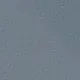
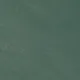
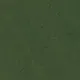
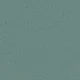
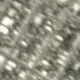
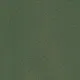
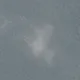
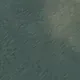
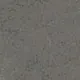
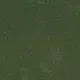
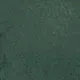
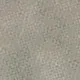
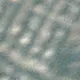
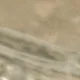
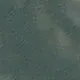
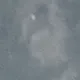
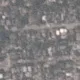
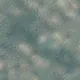
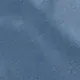
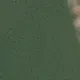
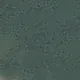
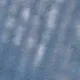
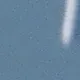
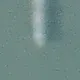
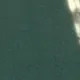
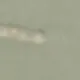
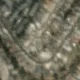
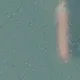
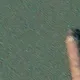
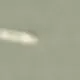
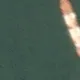
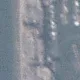
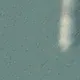
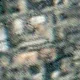
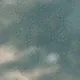
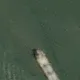
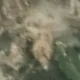
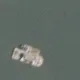
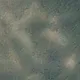
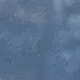
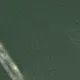
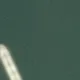
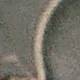
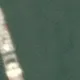
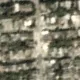
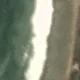
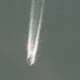
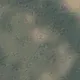
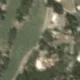
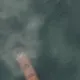
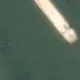
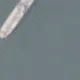
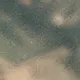
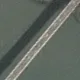
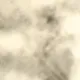
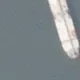
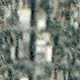
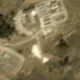
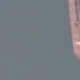
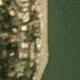
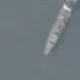
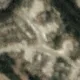
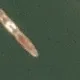
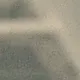
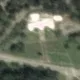
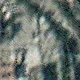
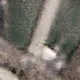
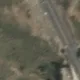
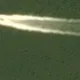
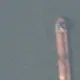
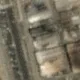
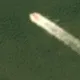
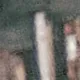
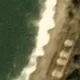
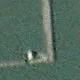
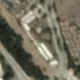
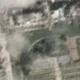
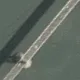
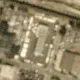
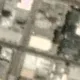
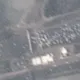
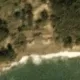
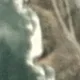
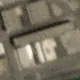
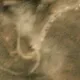
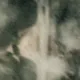
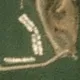
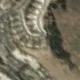
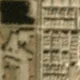
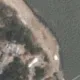
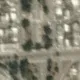
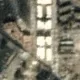
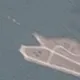
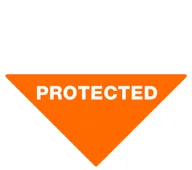
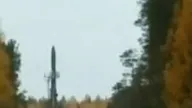
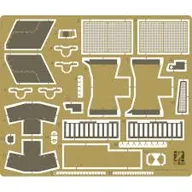

In [9]:
show(result.to_html())

In [10]:
DETECTORS = ("ood-kneighbors", "ood-domain-classifier")


def output(step: str) -> Any:
    """What `step` gave the incoming source."""
    return result.steps[step].elements["inc_src"].output


union = output("ood-union")
print(f"Test images:  {union.images}")
print(f"OOD images:   {len(union.union)} (union across all detectors), {len(union.mutual)} flagged by every one")
print()

for name in DETECTORS:
    det = output(name)
    n_ood = int(np.sum(det.is_ood))
    print(f"-- {name} --")
    print(f"  OOD count:     {n_ood} / {len(det.is_ood)}")
    print(f"  OOD percentage: {n_ood / len(det.is_ood) * 100:.1f}%")
    thr = union.thresholds[name]
    print(f"  Threshold:      {thr:.4f}" if thr is not None else "  Threshold:      none")
    print()

Test images:  500
OOD images:   103 (union across all detectors), 97 flagged by every one

-- ood-kneighbors --
  OOD count:     103 / 500
  OOD percentage: 20.6%
  Threshold:      0.3012

-- ood-domain-classifier --
  OOD count:     97 / 500
  OOD percentage: 19.4%
  Threshold:      0.4098



In [11]:
truth = [incoming_dataset.swapped(i) for i in range(len(incoming_dataset))]
planted = sum(truth)

for method in DETECTORS:
    flagged = [int(i) for i in np.flatnonzero(output(method).is_ood)]
    hits = sum(1 for i in flagged if truth[i])
    recall = hits / planted * 100 if planted else 0.0
    precision = hits / len(flagged) * 100 if flagged else 0.0
    print(
        f"{method:>18}: flagged {len(flagged):>3} of {planted} planted -- recall {recall:.0f}%, precision {precision:.0f}%"
    )

    ood-kneighbors: flagged 103 of 100 planted -- recall 100%, precision 97%
ood-domain-classifier: flagged  97 of 100 planted -- recall 97%, precision 100%


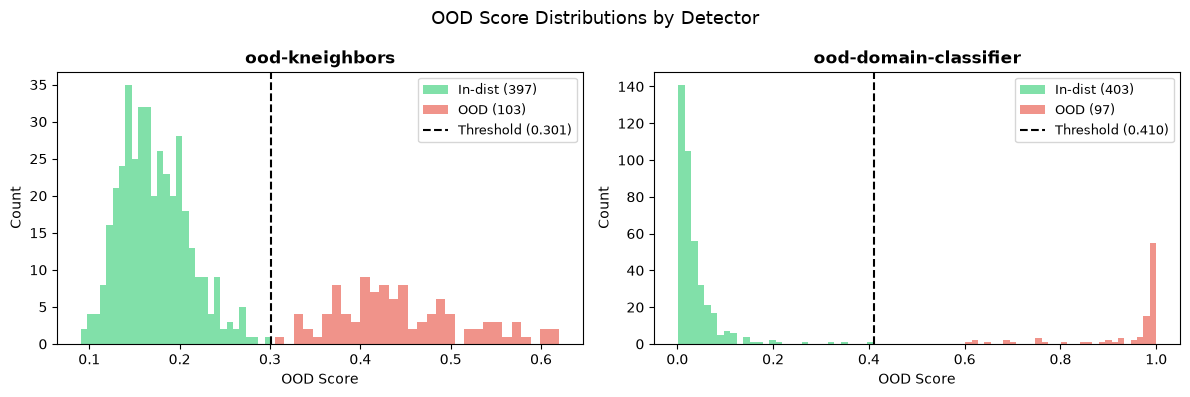

In [12]:
fig, axes = plt.subplots(1, len(DETECTORS), figsize=(6 * len(DETECTORS), 4))

for ax, method in zip(axes, DETECTORS, strict=True):
    det = output(method)
    in_scores = np.asarray(det.instance_score)[~np.asarray(det.is_ood)]
    ood_scores = np.asarray(det.instance_score)[np.asarray(det.is_ood)]

    ax.hist(in_scores, bins=30, alpha=0.6, label=f"In-dist ({len(in_scores)})", color="#2ecc71")
    ax.hist(ood_scores, bins=30, alpha=0.6, label=f"OOD ({len(ood_scores)})", color="#e74c3c")
    thr = union.thresholds[method]
    if thr is not None:
        ax.axvline(thr, color="black", linestyle="--", linewidth=1.5, label=f"Threshold ({thr:.3f})")
    ax.set_xlabel("OOD Score")
    ax.set_ylabel("Count")
    ax.set_title(method, fontsize=12, fontweight="bold")
    ax.legend(fontsize=9)

fig.suptitle("OOD Score Distributions by Detector", fontsize=13)
plt.tight_layout()
plt.show()

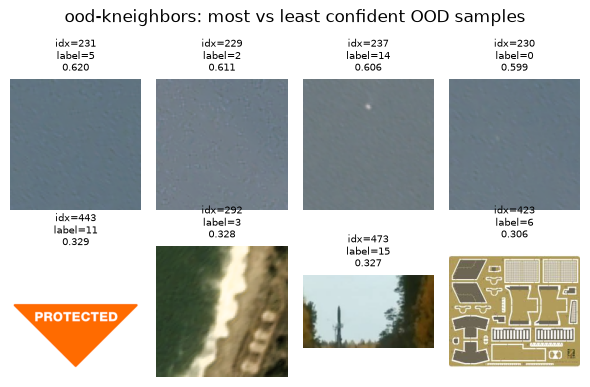

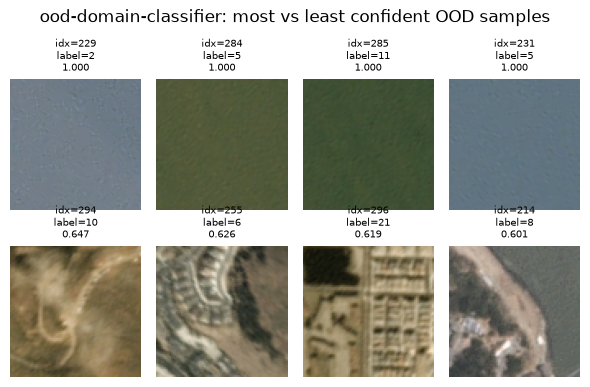

In [13]:
cols = 4

for method in DETECTORS:
    det = output(method)
    ood_samples = sorted(
        [(int(i), float(det.instance_score[i])) for i in np.flatnonzero(det.is_ood)],
        key=lambda x: -x[1],
    )
    if not ood_samples:
        continue

    top = ood_samples[:cols]
    bottom = ood_samples[-cols:]

    fig, axes = plt.subplots(2, cols, figsize=(1.5 * cols, 4))

    for row_idx, (row_label, row_items) in enumerate([("Top 4 (most OOD)", top), ("Bottom 4 (least OOD)", bottom)]):
        for col, (idx, score) in enumerate(row_items):
            img_data, target, _ = incoming_dataset[idx]
            img_arr = np.asarray(img_data)
            if img_arr.ndim == 3 and img_arr.shape[0] in (1, 3):
                img_arr = img_arr.squeeze(0) if img_arr.shape[0] == 1 else np.moveaxis(img_arr, 0, -1)
            axes[row_idx, col].imshow(img_arr, cmap="gray")
            label = int(np.argmax(target)) if np.asarray(target).ndim > 0 else int(target)
            axes[row_idx, col].set_title(f"idx={idx}\nlabel={label}\n{score:.3f}", fontsize=7)
            axes[row_idx, col].axis("off")
        for col in range(len(row_items), cols):
            axes[row_idx, col].axis("off")
        axes[row_idx, 0].set_ylabel(row_label, fontsize=8)

    fig.suptitle(f"{method}: most vs least confident OOD samples", fontsize=12)
    plt.tight_layout()
    plt.show()

In [14]:
predictors = output("factor-predictors").factors
if predictors:
    print("Factor Predictors (mutual information with OOD status):")
    print("-" * 50)
    for factor, mi in predictors.items():
        bar = "#" * int(mi * 20)
        print(f"  {factor:20s}  {mi:.4f} bits  {bar}")
    print()

deviations = output("factor-deviation").items
if deviations:
    print(f"Factor Deviations (top {min(10, len(deviations))} OOD images):")
    print("-" * 50)
    for dev in deviations[:10]:
        top_factors = list(dev.deviations.items())[:3]
        factors_str = ", ".join(f"{k}={v:.2f}" for k, v in top_factors)
        print(f"  Image {dev.index:4d}: {factors_str}")

Factor Predictors (mutual information with OOD status):
--------------------------------------------------
  f_size                0.9317 bits  ##################
  f_height              0.9305 bits  ##################
  f_width               0.9305 bits  ##################
  f_zeros               0.8110 bits  ################
  f_aspect_ratio        0.6248 bits  ############
  f_sharpness           0.6135 bits  ############
  f_std                 0.6038 bits  ############
  f_var                 0.6019 bits  ############
  f_darkness            0.3681 bits  #######
  f_contrast            0.3212 bits  ######
  f_entropy             0.2808 bits  #####
  f_kurtosis            0.1842 bits  ###
  f_brightness          0.1368 bits  ##
  f_skew                0.1084 bits  ##
  f_mean                0.0950 bits  #
  class_label           0.0000 bits  
  height                0.0000 bits  
  width                 0.0000 bits  

Factor Deviations (top 10 OOD images):
-------------------------

In [15]:
NOISY_CLASSES = [1, 5, 11, 16, 23]


class NoisyClasses:
    """Adds heavy sensor noise to frames of the named classes."""

    def __init__(self, dataset: Any, classes: list[int], sigma: float = 60.0) -> None:
        self._dataset = dataset
        self._classes = set(classes)
        self._sigma = sigma
        self._rng = np.random.default_rng(0)
        self.metadata = {"id": "noisy_classes", "original_metadata": dataset.metadata}

    def __len__(self) -> int:
        return len(self._dataset)

    def corrupted(self, index: int) -> bool:
        return int(np.argmax(self._dataset[index][1])) in self._classes

    def __getitem__(self, index: int) -> tuple[NDArray[Any], Any, Mapping[str, Any]]:
        image, target, metadata = self._dataset[index]
        if int(np.argmax(target)) in self._classes:
            noise = self._rng.normal(0, self._sigma, np.asarray(image).shape)
            image = np.clip(np.asarray(image).astype(np.int16) + noise, 0, 255).astype(np.asarray(image).dtype)
        return image, target, metadata


noisy_dataset = NoisyClasses(View(vehicles_raw, [Indices(_order[2000:2500])]), NOISY_CLASSES)
print(f"Corrupting: {[index2label[c] for c in NOISY_CLASSES]}")

noisy_task = TaskConfig(
    name="vehicles-ood-noise",
    workflow="vehicles-ood",
    sources=["ref_src", "noisy_src"],
    extractor="resnet18",
)
noisy_config = config.model_copy(
    update={
        "datasets": [ref_config, DatasetProtocolConfig(name="noisy", format="maite", dataset=noisy_dataset)],
        "sources": [
            SourceConfig(name="ref_src", dataset="reference"),
            SourceConfig(name="noisy_src", dataset="noisy"),
        ],
        "tasks": [noisy_task],
    }
)

noisy_result = run_task(noisy_config, noisy_task, cache_dir=Path("./cache"))

Corrupting: ['30N6E', 'BMP-2', 'D-30', 'T-14', 'TOS-1']


/builds/jatic/aria/dataeval-flow/src/dataeval_flow/steps/combines/_factors.py:55: UserWarning: `height` and `width` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"height": [...]} to control this.
  rows = metadata.rows_at(metadata.item_level)


In [16]:
noisy_truth = [noisy_dataset.corrupted(i) for i in range(len(noisy_dataset))]
noisy_planted = sum(noisy_truth)

for method in DETECTORS:
    flagged = [int(i) for i in np.flatnonzero(noisy_result.steps[method].elements["noisy_src"].output.is_ood)]
    hits = sum(1 for i in flagged if noisy_truth[i])
    recall = hits / noisy_planted * 100 if noisy_planted else 0.0
    precision = hits / len(flagged) * 100 if flagged else 0.0
    print(
        f"{method:>18}: flagged {len(flagged):>3} of {noisy_planted} corrupted -- recall {recall:.0f}%, precision {precision:.0f}%"
    )

    ood-kneighbors: flagged  43 of 93 corrupted -- recall 44%, precision 95%
ood-domain-classifier: flagged  93 of 93 corrupted -- recall 100%, precision 100%


In [17]:
json_str = result.export(fmt="json")
print(f"JSON output: {len(json_str)} characters")
print(json_str[:600] + "\n...")

JSON output: 307797 characters
{
  "kind": "workflow",
  "metadata": {
    "version": "1.0",
    "timestamp": "2026-11-12T08:45:23.250669Z",
    "dataset_id": "reference,incoming",
    "label_source": "protocol",
    "model_id": "resnet18 (torch)",
    "preprocessor_id": "imagenet",
    "selection_id": null,
    "source_descriptions": [
      "ref_src (reference)",
      "inc_src (incoming)"
    ],
    "resolved_config": {
      "sources": [
        {
          "name": "ref_src",
          "dataset": "reference",
          "dataset_config": {
            "name": "reference",
            "format": "maite",
            "versi
...
